In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# laoding the tables
orders = pd.read_csv(r"C:\Users\faizs\Documents\DATA ANALYTICS PROJECTS\Project 3 — Quick Commerce Operations Intelligence\qc_orders.csv")
items = pd.read_csv(r"C:\Users\faizs\Documents\DATA ANALYTICS PROJECTS\Project 3 — Quick Commerce Operations Intelligence\qc_order_items.csv")
inventory = pd.read_csv(r"C:\Users\faizs\Documents\DATA ANALYTICS PROJECTS\Project 3 — Quick Commerce Operations Intelligence\qc_inventory.csv")

# fix date columns
orders['order_date'] = pd.to_datetime(orders['order_date'])
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])
inventory['week_start_date'] = pd.to_datetime(inventory['week_start_date'])

# Replace -1 with NaN for cancelled orders
orders['actual_delivery_mins'] = orders['actual_delivery_mins'].replace(-1,np.nan)

print("Orders: ",orders.shape)
print("Items: ",items.shape)
print("Inventory: ",inventory.shape)
print("\n Orders columns: ",orders.columns.tolist())



Orders:  (15000, 16)
Items:  (40333, 9)
Inventory:  (34320, 11)

 Orders columns:  ['order_id', 'customer_id', 'dark_store_id', 'city', 'zone', 'order_timestamp', 'order_date', 'order_hour', 'order_day_of_week', 'promised_delivery_mins', 'actual_delivery_mins', 'delivery_status', 'order_value', 'delivery_fee', 'payment_method', 'n_items']


In [3]:
print("=== ORDERS OVERVIEW ===")
print(f"Total Orders: {len(orders):,}")
print(f"Date Range: {orders['order_date'].min()} to {orders['order_date'].max()}")
print(f"Total Revenue: ₹{orders[orders['delivery_status']!='Cancelled']['order_value'].sum():,.0f}")
print(f"Avg Order Value: ₹{orders['order_value'].mean():,.0f}")
print(f"\nDelivery Status:")
print(orders['delivery_status'].value_counts())
print(f"\nCancellation Rate: {(orders['delivery_status']=='Cancelled').mean()*100:.2f}%")
print(f"SLA Breach Rate: {(orders['delivery_status']=='Delivered Late').sum() / (orders['delivery_status']!='Cancelled').sum()*100:.2f}%")

print("\n=== MISSING VALUES ===")
print(orders.isnull().sum()[orders.isnull().sum()>0])

=== ORDERS OVERVIEW ===
Total Orders: 15,000
Date Range: 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Total Revenue: ₹8,541,430
Avg Order Value: ₹588

Delivery Status:
delivery_status
Delivered Late       11441
Delivered On Time     3105
Cancelled              454
Name: count, dtype: int64

Cancellation Rate: 3.03%
SLA Breach Rate: 78.65%

=== MISSING VALUES ===
actual_delivery_mins    454
dtype: int64


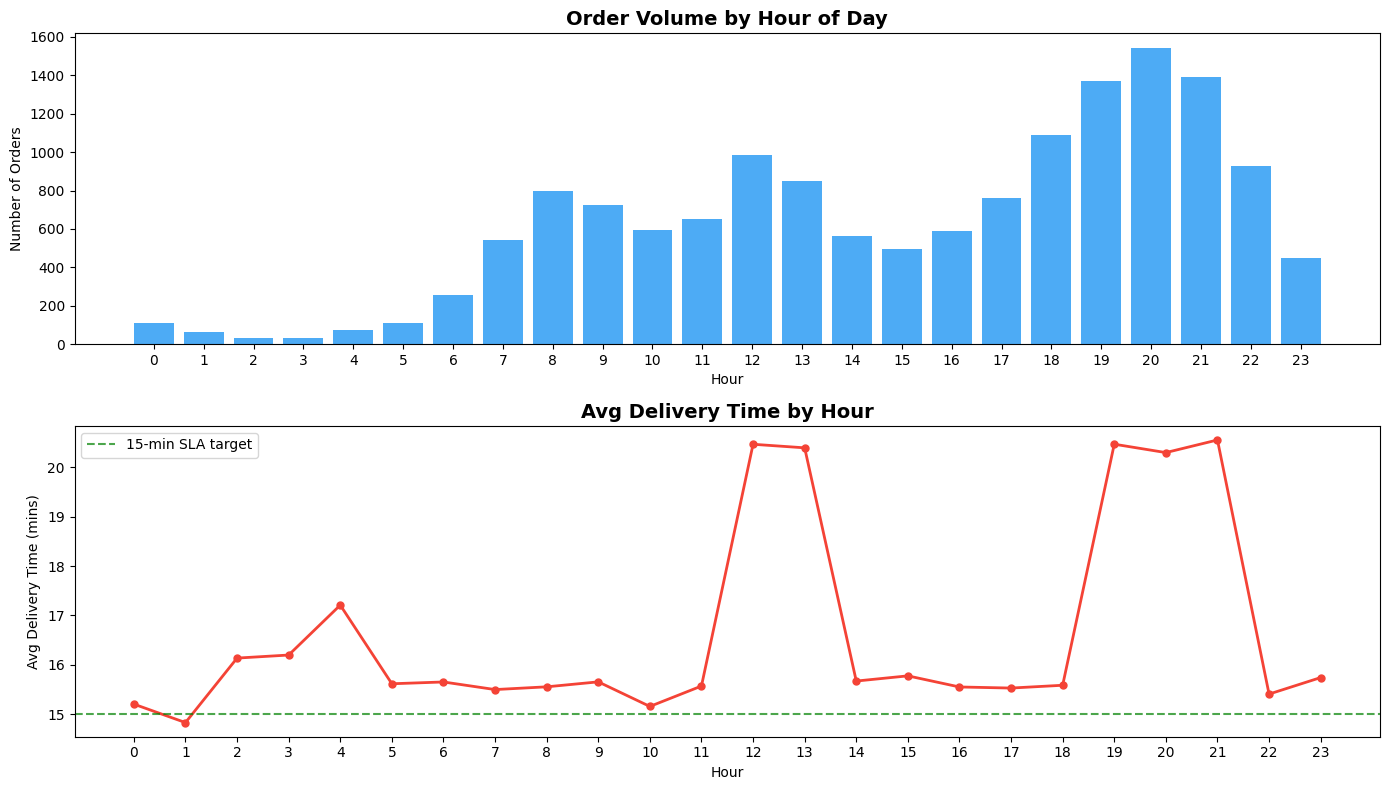

Chart saved.


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Chart 1 - Order volume by hour
hourly = orders.groupby('order_hour')['order_id'].count().reset_index()
axes[0].bar(hourly['order_hour'], hourly['order_id'], color='#2196F3', alpha=0.8)
axes[0].set_title('Order Volume by Hour of Day', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Number of Orders')
axes[0].set_xticks(range(0, 24))

# Chart 2 - Avg delivery time by hour
delivered = orders[orders['actual_delivery_mins'].notna()]
hourly_delivery = delivered.groupby('order_hour')['actual_delivery_mins'].mean().reset_index()
axes[1].plot(hourly_delivery['order_hour'], hourly_delivery['actual_delivery_mins'], 
             color='#F44336', linewidth=2, marker='o', markersize=5)
axes[1].axhline(y=15, color='green', linestyle='--', alpha=0.7, label='15-min SLA target')
axes[1].set_title('Avg Delivery Time by Hour', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Avg Delivery Time (mins)')
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.tight_layout()
plt.savefig('hourly_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved.")

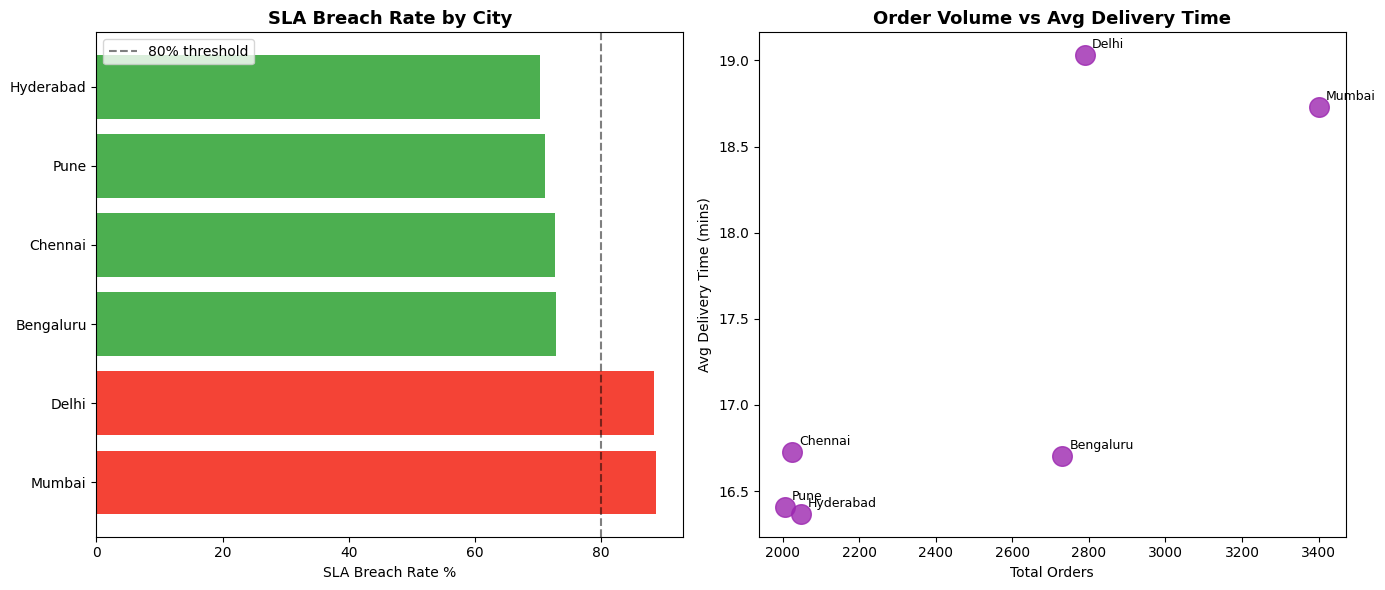

Done.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Data prep
city_stats = orders.groupby('city').agg(
    total_orders=('order_id', 'count'),
    sla_breach_rate=('delivery_status', lambda x: (x=='Delivered Late').sum() / (x!='Cancelled').sum() * 100),
    avg_delivery=('actual_delivery_mins', 'mean')
).reset_index().sort_values('sla_breach_rate', ascending=False)

# Chart 1 - SLA breach rate by city
colors = ['#F44336' if x > 85 else '#FF9800' if x > 75 else '#4CAF50' for x in city_stats['sla_breach_rate']]
axes[0].barh(city_stats['city'], city_stats['sla_breach_rate'], color=colors)
axes[0].axvline(x=80, color='black', linestyle='--', alpha=0.5, label='80% threshold')
axes[0].set_title('SLA Breach Rate by City', fontsize=13, fontweight='bold')
axes[0].set_xlabel('SLA Breach Rate %')
axes[0].legend()

# Chart 2 - Orders vs avg delivery scatter
axes[1].scatter(city_stats['total_orders'], city_stats['avg_delivery'], 
                s=200, color='#9C27B0', alpha=0.8)
for _, row in city_stats.iterrows():
    axes[1].annotate(row['city'], (row['total_orders'], row['avg_delivery']),
                     textcoords='offset points', xytext=(5, 5), fontsize=9)
axes[1].set_title('Order Volume vs Avg Delivery Time', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total Orders')
axes[1].set_ylabel('Avg Delivery Time (mins)')

plt.tight_layout()
plt.savefig('city_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done.")

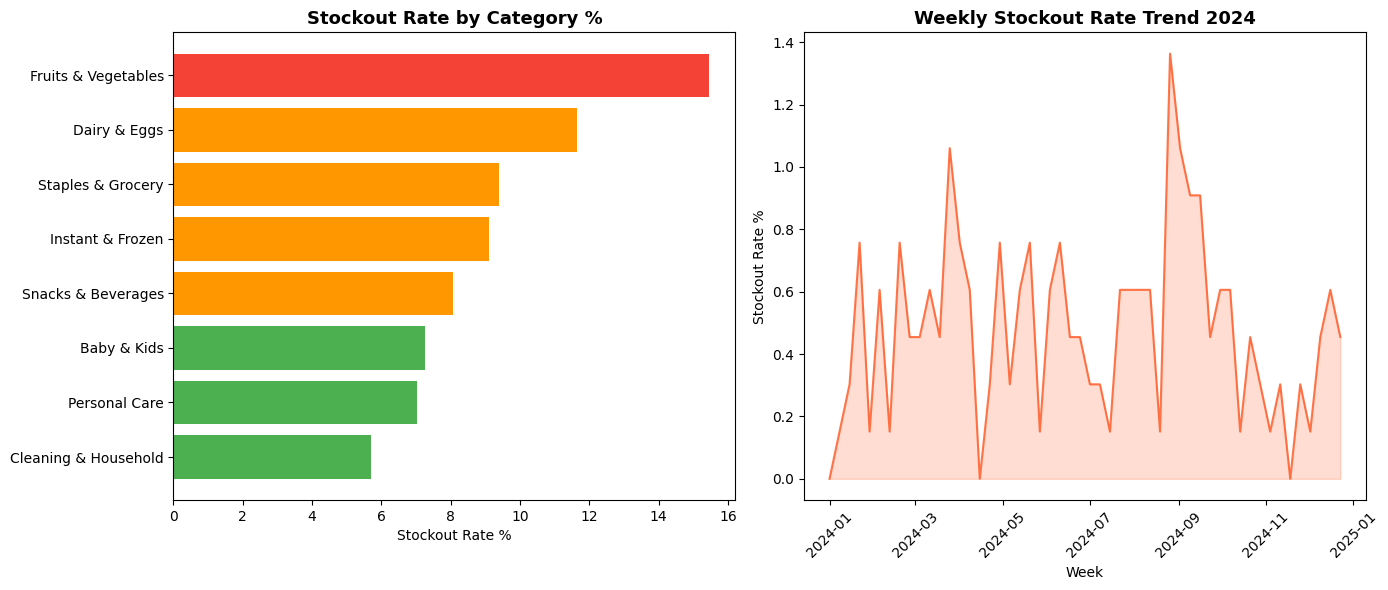

Done.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1 - Stockout rate by category (from items table)
cat_stockout = items.groupby('category').agg(
    total_items=('item_id', 'count'),
    stockouts=('stockout_flag', 'sum')
).reset_index()
cat_stockout['stockout_rate'] = cat_stockout['stockouts'] / cat_stockout['total_items'] * 100
cat_stockout = cat_stockout.sort_values('stockout_rate', ascending=True)

colors = ['#F44336' if x > 12 else '#FF9800' if x > 8 else '#4CAF50' for x in cat_stockout['stockout_rate']]
axes[0].barh(cat_stockout['category'], cat_stockout['stockout_rate'], color=colors)
axes[0].set_title('Stockout Rate by Category %', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Stockout Rate %')

# Chart 2 - Weekly stockout trend (inventory table)
weekly = inventory.groupby('week_start_date').agg(
    stockouts=('stockout_occurred', 'sum'),
    total=('inventory_id', 'count')
).reset_index()
weekly['stockout_rate'] = weekly['stockouts'] / weekly['total'] * 100

axes[1].plot(weekly['week_start_date'], weekly['stockout_rate'], 
             color='#FF5722', linewidth=1.5, alpha=0.8)
axes[1].fill_between(weekly['week_start_date'], weekly['stockout_rate'], 
                      alpha=0.2, color='#FF5722')
axes[1].set_title('Weekly Stockout Rate Trend 2024', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Week')
axes[1].set_ylabel('Stockout Rate %')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('stockout_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done.")

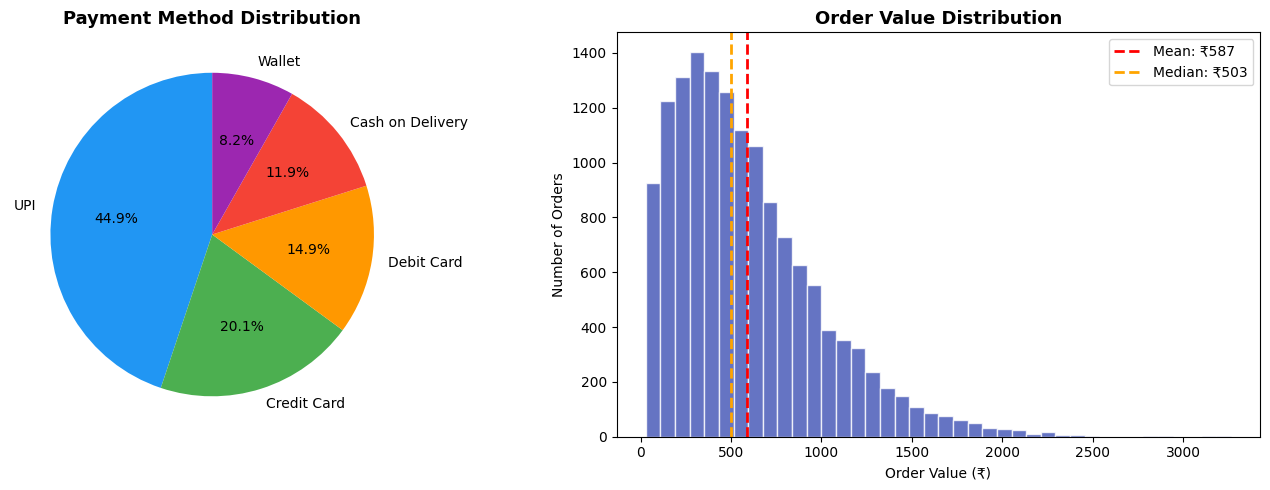

Done.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1 - Payment method breakdown
payment = orders['payment_method'].value_counts()
axes[0].pie(payment.values, labels=payment.index, autopct='%1.1f%%',
            colors=['#2196F3','#4CAF50','#FF9800','#F44336','#9C27B0'],
            startangle=90)
axes[0].set_title('Payment Method Distribution', fontsize=13, fontweight='bold')

# Chart 2 - Order value distribution
delivered_orders = orders[orders['delivery_status'] != 'Cancelled']
axes[1].hist(delivered_orders['order_value'], bins=40, color='#3F51B5', alpha=0.8, edgecolor='white')
axes[1].axvline(delivered_orders['order_value'].mean(), color='red', 
                linestyle='--', linewidth=2, label=f"Mean: ₹{delivered_orders['order_value'].mean():.0f}")
axes[1].axvline(delivered_orders['order_value'].median(), color='orange',
                linestyle='--', linewidth=2, label=f"Median: ₹{delivered_orders['order_value'].median():.0f}")
axes[1].set_title('Order Value Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Order Value (₹)')
axes[1].set_ylabel('Number of Orders')
axes[1].legend()

plt.tight_layout()
plt.savefig('payment_ordervalue.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done.")

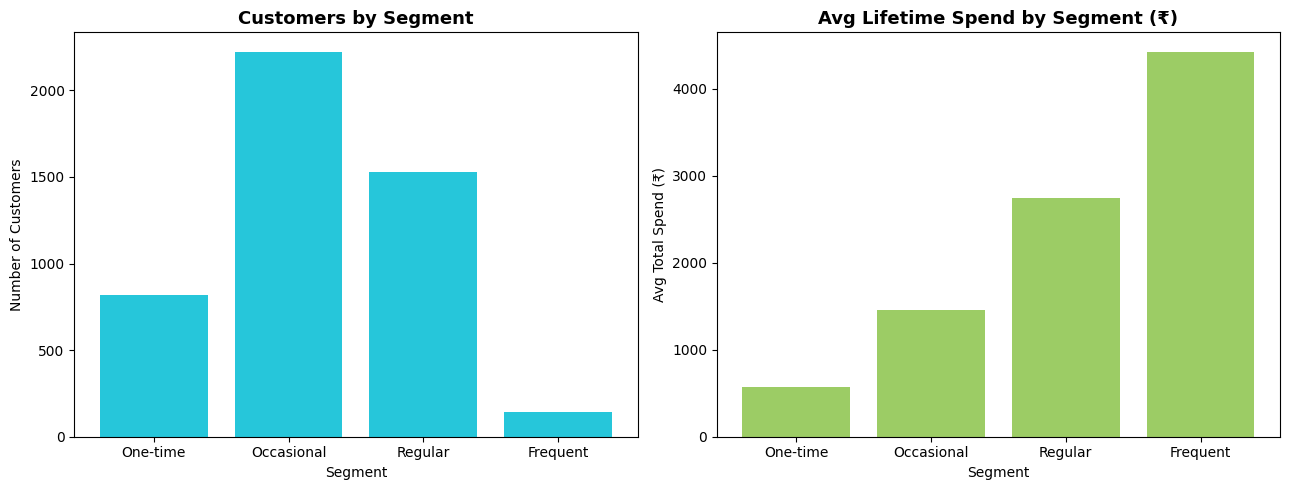

Exported 15,000 rows
Python EDA complete!


In [8]:
# Customer segments
customer_stats = orders[orders['delivery_status']!='Cancelled'].groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    total_spent=('order_value', 'sum'),
    avg_order_value=('order_value', 'mean')
).reset_index()

customer_stats['segment'] = pd.cut(
    customer_stats['total_orders'],
    bins=[0, 1, 3, 6, 10, 999],
    labels=['One-time', 'Occasional', 'Regular', 'Frequent', 'Power User']
)

# Chart
seg_summary = customer_stats.groupby('segment', observed=True).agg(
    customers=('customer_id', 'count'),
    avg_spent=('total_spent', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(seg_summary['segment'], seg_summary['customers'], color='#00BCD4', alpha=0.85)
axes[0].set_title('Customers by Segment', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Number of Customers')

axes[1].bar(seg_summary['segment'], seg_summary['avg_spent'], color='#8BC34A', alpha=0.85)
axes[1].set_title('Avg Lifetime Spend by Segment (₹)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Segment')
axes[1].set_ylabel('Avg Total Spend (₹)')

plt.tight_layout()
plt.savefig('customer_segments.png', dpi=150, bbox_inches='tight')
plt.show()

# Export clean file
orders['month'] = orders['order_date'].dt.to_period('M').astype(str)
orders['is_sla_breach'] = (orders['delivery_status'] == 'Delivered Late').astype(int)
orders['is_cancelled'] = (orders['delivery_status'] == 'Cancelled').astype(int)

orders.to_csv(r'C:\Users\faizs\Downloads\qc_orders_clean.csv', index=False)
print(f"Exported {len(orders):,} rows")
print("Python EDA complete!")